качаем библиотеки

In [1]:
import pandas as pd
import numpy as np

import statistics
import statsmodels.api as sm

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm
from scipy.stats import t

#### Проект
Наша кампания ранне имела всего один продукт, он был запущен давно. У нас есть записи сколько выручки нам приносил этот продукт за каждый день его работы. Пару месяцев назад кампания запустила второй продукт, и так же ежедневно фиксировала выручку которую он нам приносил. Данные по выручкам сохранены ниже в переменных product1 и product2.<br>
Наша задача сделать полный анализ на основе всего лишь этих двух списках.

In [2]:
### для загрузки данных
with open(r'f679079d4ee2fe0060716778a66602bd.txt', 'r') as fp:
    for i, line in enumerate(fp):
        if i == 0:
            product1 = [int(i) for i in line.split(' ')]
        if i == 1:
            product2 = [int(i) for i in line.split(' ')]

fp.close()

**Задача 1**<br>
подсчитайте среднее арифметическое (mean), медиану и моду для обоих списков: product1 и product2

In [3]:
print('Продукт 1:')
print('Среднее:', statistics.mean(product1))
print('Медиана:', statistics.median(product1))
print('Мода:', statistics.mode(product1))
print()

print('Продукт 2:')
print('Среднее:', statistics.mean(product2))
print('Медиана:', statistics.median(product2))
print('Мода:', statistics.multimode(product2))

Продукт 1:
Среднее: 199.103
Медиана: 198.5
Мода: 186

Продукт 2:
Среднее: 193.5
Медиана: 194.5
Мода: [227, 170, 232, 146]


Какая из трех метрик будет наименее показательной, и почему?<br>
На основе оставшихся двух метрик какой продукт в среднем приносит больше выручки?

In [4]:
#Наименее показательной метрикой является мода, поскольку значения выручки сильно варьируются, а у второго продукта имеется сразу несколько мод. 
#По среднему и медиане продукт 1 в среднем приносит больше выручки: его среднее равно 199.103, медиана — 198.5, а у продукта 2 — 193.5 и 194.5.

**Задача 2**<br>
подсчитайте стандартное отклонение и скажите оценка какого продукта является более точной?

In [6]:
std_product1 = np.std(product1)
std_product2 = np.std(product2)

print('Стандартное отклонение продукта 1:', std_product1)
print('Стандартное отклонение продукта 2:', std_product2)

#Выручка продукта 1 немного менее разбросана относительно среднего значения, однако разница между продуктами небольшая.

Стандартное отклонение продукта 1: 28.793964489107783
Стандартное отклонение продукта 2: 29.589018233121557


**Задача 3**<br>
Нарисуйте распределение вероятности выручки для продукта1 и для продукта2.<br>
Можете использовать гистограмму или kdeplot

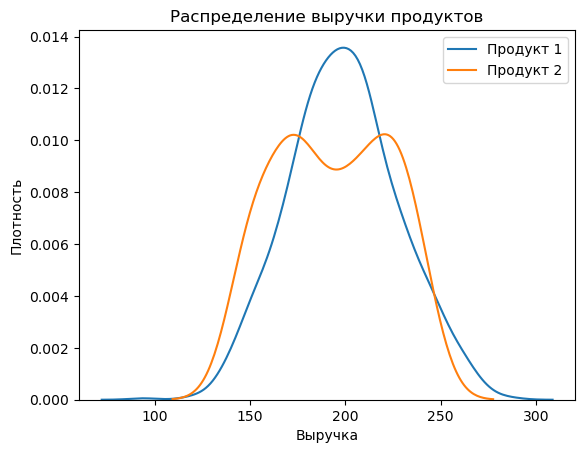

In [28]:
sns.kdeplot(product1, label = 'Продукт 1')
sns.kdeplot(product2, label = 'Продукт 2')
plt.xlabel('Выручка')
plt.ylabel('Плотность')
plt.title('Распределение выручки продуктов')
plt.legend()
plt.show()

**Задача 4**<br>
Посчитайте размах выручки для продукта1 и для продукта2<br>
Сходится ли разница в размахах и разница в стандартных отклонениях, какая может быть причина?

In [9]:
range_product1 = max(product1) - min(product1)
range_product2 = max(product2) - min(product2)

print('Размах продукта 1:', range_product1)
print('Размах продукта 2:', range_product2)

#Размах продукта 1 значительно больше из-за наличия крайних значений и выбросов. 
#Размах зависит только от минимального и максимального значения, тогда как стандартное отклонение учитывает весь набор данных.

Размах продукта 1: 193
Размах продукта 2: 97


**Задача 5**<br>
Посчитайте межквартильный разммах IQR для продукта1 и продукта2<br>
Теперь убрав выбросы что мы можем сказать о разбросе данных?

In [11]:
Q1_product1 = np.percentile(product1, 25)
Q3_product1 = np.percentile(product1, 75)
IQR_product1 = Q3_product1 - Q1_product1

Q1_product2 = np.percentile(product2, 25)
Q3_product2 = np.percentile(product2, 75)
IQR_product2 = Q3_product2 - Q1_product2

print('IQR продукта 1:', IQR_product1)
print('IQR продукта 2:', IQR_product2)

#После уменьшения влияния выбросов видно, что центральные значения выручки продукта 2 имеют больший разброс.

IQR продукта 1: 38.25
IQR продукта 2: 51.0


**Задача 6**<br>
Нарисуйте box-plot для продукта1 и с рисунка скажите при каких значениях начинаются выбросы

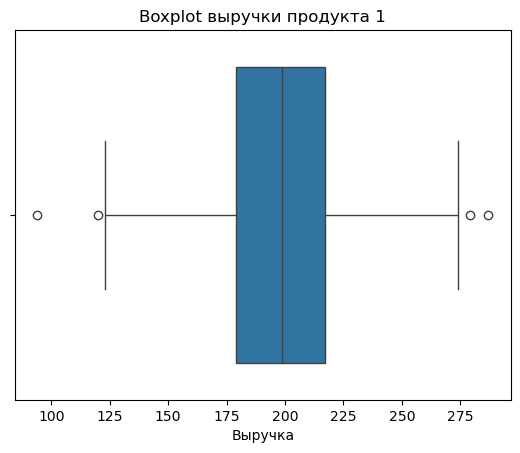

Нижняя граница: 121.625
Верхняя граница: 274.625


In [29]:
sns.boxplot(x = product1)
plt.title('Boxplot выручки продукта 1')
plt.xlabel('Выручка')
plt.show()

lower_bound = Q1_product1 - 1.5 * IQR_product1
upper_bound = Q3_product1 + 1.5 * IQR_product1

print('Нижняя граница:', lower_bound)
print('Верхняя граница:', upper_bound)

#Выбросы начинаются при значениях ниже 121.625 и выше 274.625.

**Задача 7**<br>
Нарисуйте QQ plot выручки для обоих продуктов<br>
Какое из распределений является нормальным?

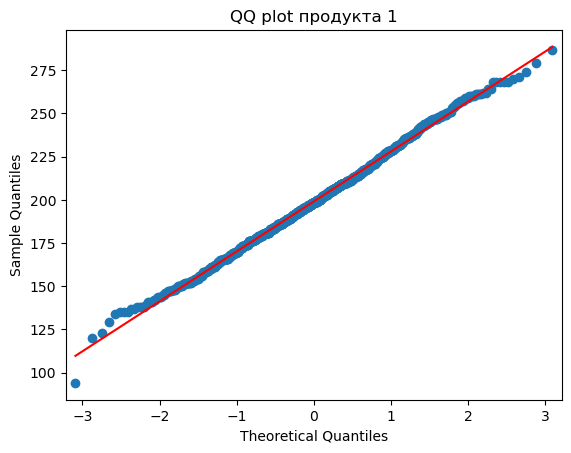

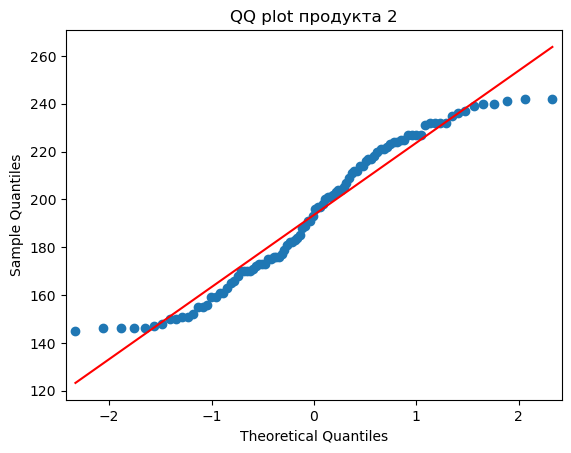

In [30]:
sm.qqplot(np.array(product1), line = 'r')
plt.title('QQ plot продукта 1')
plt.show()

sm.qqplot(np.array(product2), line = 'r')
plt.title('QQ plot продукта 2')
plt.show()

#Распределение выручки продукта 1 можно считать близким к нормальному, поскольку большая часть точек располагается вдоль прямой линии.

Каких значений много или наоборот не достает в продукте2 чтобы значения стали нормально распределенными?

In [17]:
#Наблюдается избыток значений в областях примерно 145–150 и 235–242 и недостаток промежуточных значений, 
#которые позволили бы распределению лучше соответствовать нормальному.

**Задача 8**<br>
И так мы знаем что выручка продукта1 является нормально распредленной, переведите все значения в стандартное нормальное распределение используя текущие mean и std<br>
создайте новую переменнуя и запишите новые значения туда

In [18]:
mean_product1 = np.mean(product1)
std_product1 = np.std(product1)

product1_standardized = (np.array(product1) - mean_product1) / std_product1

print(product1_standardized)

[-1.07765640e-01  6.56283368e-01 -3.83066389e-02  8.29930870e-01
 -1.18438015e+00 -5.93978645e-01  2.01073388e+00  5.17365367e-01
 -7.30361393e-02  1.80235688e+00 -1.77224640e-01 -3.83066389e-02
  1.35340863e-01  1.90654538e+00 -3.85601642e-01  1.07303737e+00
  7.25742369e-01 -2.43464216e+00 -6.28708145e-01  2.14965188e+00
  1.31614388e+00 -1.07765640e-01  4.13176866e-01 -2.81413141e-01
  2.39275839e+00 -1.84424066e+00 -5.93978645e-01  1.10776687e+00
 -1.07765640e-01  6.91012869e-01  4.47906366e-01  5.52094867e-01
  6.56283368e-01  1.48979138e+00  8.99389871e-01  2.39275839e+00
  2.04799864e-01 -7.32896646e-01  5.52094867e-01  9.68848871e-01
 -6.98167146e-01  3.11523618e-02  1.00611363e-01 -1.07765640e-01
 -3.57713854e-03  6.21553868e-01 -1.18438015e+00 -5.24519644e-01
 -3.16142642e-01  1.00611363e-01  1.28141437e+00  3.11523618e-02
  6.91012869e-01  3.43717865e-01  7.60471869e-01  2.04799864e-01
  3.78447365e-01 -6.28708145e-01 -3.57713854e-03 -6.63437645e-01
  1.70070363e-01 -8.71814

Нарисуйте kdeplot нового стандартного распределения

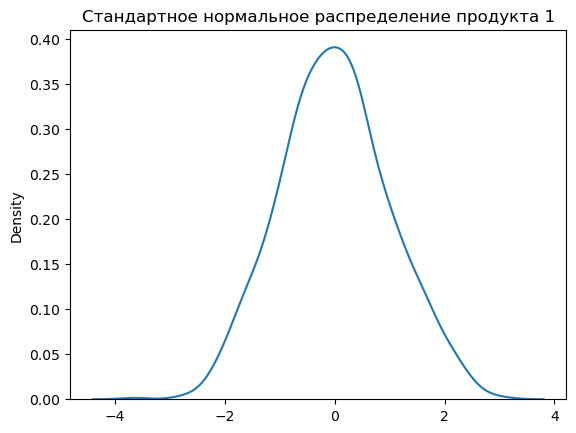

In [20]:
sns.kdeplot(product1_standardized)
plt.title('Стандартное нормальное распределение продукта 1')
plt.show()

**Задача 9**<br>
Подсчитайте точку слева от которой будет 1% всей вероятности распределения

In [21]:
point = norm.ppf(0.01)
print(point)

-2.3263478740408408


Первое значение в списке product1 равно 94. Когда мы преобразуем список в стандартное нормальное распределение, 94 преобразуется в -3.65<br>
Что нам говорит это число, особенно при сравнении с точкой которую мы только что подсчитали?

In [22]:
#Поскольку −3.65 меньше точки −2.326, это значение попадает в область, содержащую менее 1% самых низких значений распределения.

**Задача 10**<br>
Продукт2 новый, но уже достаточно стабилизирвался за эти месяцы. Мы хотим знать сколько он будет в среднем нам приносить ежедневно выручки и в будущем.<br>
Дайте точечную оценку средней выручке продукта2

In [23]:
point_estimate = np.mean(product2)
print('Точечная оценка:', point_estimate)

Точечная оценка: 193.5


Подсчитайте 95% доверительный интервал

In [31]:
mean_product2 = np.mean(product2)
std_product2 = np.std(product2, ddof = 1)
n = len(product2)
confidence_interval = t.interval(0.95, df = n-1, loc = mean_product2, scale = std_product2 / np.sqrt(n))
print(confidence_interval)

(np.float64(187.59931931126806), np.float64(199.40068068873194))


**Задача11**<br>
Проведите АБ тест с уровнем значимости 5% что средняя выручка у продукта1 выше чем 197.5

In [33]:
mean_product1 = np.mean(product1)
std_product1 = np.std(product1, ddof = 1)
n = len(product1)

print(mean_product1)
print(std_product1)
print(n)

t_statistic = ((mean_product1 - 197.5) / (std_product1 / np.sqrt(n)))

print(t_statistic)

p_value = t.sf(t_statistic, df = n - 1)

print(p_value)

alpha = 0.05

if p_value < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не отвергаем нулевую гипотезу')

199.103
28.808372278095014
1000
1.759603437610513
0.039390559624344984
Отвергаем нулевую гипотезу


Какой это был типа АБ теста?

In [34]:
#Одновыборочный односторонний t-тест.

**Задача12**<br>
Проведите АБ тест с уровнем значимости 5% что средняя выручка у продукта1 и у продукта2 равны

In [48]:
mean1 = np.mean(product1)
mean2 = np.mean(product2)
std1 = np.std(product1, ddof = 1)
std2 = np.std(product2, ddof = 1)

n1 = len(product1)
n2 = len(product2)

standard_error = np.sqrt(std1**2 / n1 + std2**2 / n2)

t_statistic = (mean1 - mean2) / standard_error

# Степени свободы
df = ((std1**2 / n1 + std2**2 / n2)**2 / ((std1**2 / n1)**2 / (n1 - 1) + (std2**2 / n2)**2 / (n2 - 1)))

p_value = 2 * t.sf(abs(t_statistic), df=df)

print('Среднее продукта 1:', mean1)
print('Среднее продукта 2:', mean2)
print('t-статистика:', t_statistic)
print('p-value:', p_value)

alpha = 0.05

if p_value < alpha:
    print('\nОтвергаем нулевую гипотезу.')
    print('Средняя выручка продуктов статистически значимо различается.')
else:
    print('\nНе отвергаем нулевую гипотезу.')
    print('Статистически значимых различий между средней выручкой продуктов не обнаружено.')

Среднее продукта 1: 199.103
Среднее продукта 2: 193.5
t-статистика: 1.8014812850572308
p-value: 0.07417305124776177

Не отвергаем нулевую гипотезу.
Статистически значимых различий между средней выручкой продуктов не обнаружено.
